## Step 1 – Import Required Libraries

### Import the necessary Python libraries for data manipulation, numerical operations and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 2 – Load Final EDA Dataset

Load the cleaned and processed customer RFM dataset exported from the Exploratory Data Analysis notebook.

In [2]:
rfm = pd.read_csv("customer_rfm_eda.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", rfm.shape)

rfm.head()

Dataset loaded successfully!
Dataset Shape: (93358, 9)


,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,141.90,4,1,3,8,Loyal Customers
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,27.19,3,1,1,5,At Risk
2,0000f46a3911fa3c0805444483337064,536,1,86.22,1,1,2,4,At Risk
3,0000f6ccb0745a6a4b88665a16c9f078,320,1,43.62,2,1,1,4,At Risk
4,0004aac84e0df4da2b147fca70cf8255,287,1,196.89,2,1,4,7,Potential Customers


## Step 3 – Inspect Dataset and Data Types

Understand the structure of the dataset, identify column data types and examine the memory usage.

In [3]:
print("Dataset Information:\n")
rfm.info()

print("\nDataset Data Types:\n")
print(rfm.dtypes)

print("\nDataset Shape:", rfm.shape)

Dataset Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93358 entries, 0 to 93357
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_unique_id  93358 non-null  object 
 1   Recency             93358 non-null  int64  
 2   Frequency           93358 non-null  int64  
 3   Monetary            93358 non-null  float64
 4   R_Score             93358 non-null  int64  
 5   F_Score             93358 non-null  int64  
 6   M_Score             93358 non-null  int64  
 7   RFM_Score           93358 non-null  int64  
 8   Customer_Segment    93358 non-null  object 
dtypes: float64(1), int64(6), object(2)
memory usage: 6.4+ MB

Dataset Data Types:

customer_unique_id     object
Recency                 int64
Frequency               int64
Monetary              float64
R_Score                 int64
F_Score                 int64
M_Score                 int64
RFM_Score               int64
Custome

## Step 4 – Check Missing Values and Duplicate Records

Identify missing values, duplicate rows and duplicate customer IDs to ensure data consistency before creating new features.

In [4]:
print("Missing Values:")
print(rfm.isnull().sum())

print("\nTotal Missing Values:", rfm.isnull().sum().sum())

print("\nDuplicate Rows:", rfm.duplicated().sum())

print("\nDuplicate Customer IDs:",
      rfm["customer_unique_id"].duplicated().sum())

Missing Values:
customer_unique_id    0
Recency               0
Frequency             0
Monetary              0
R_Score               0
F_Score               0
M_Score               0
RFM_Score             0
Customer_Segment      0
dtype: int64

Total Missing Values: 0

Duplicate Rows: 0

Duplicate Customer IDs: 0


## Step 5 – Create New Customer Features

Create additional customer-level features using existing Recency, Frequency and Monetary values to improve customer analysis.

In [5]:
# Feature 1: Average Spending Per Order

rfm["Average_Spending_Per_Order"] = (
    rfm["Monetary"] / rfm["Frequency"]
)

rfm.head()

,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment,Average_Spending_Per_Order
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,141.90,4,1,3,8,Loyal Customers,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,27.19,3,1,1,5,At Risk,27.19
2,0000f46a3911fa3c0805444483337064,536,1,86.22,1,1,2,4,At Risk,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,320,1,43.62,2,1,1,4,At Risk,43.62
4,0004aac84e0df4da2b147fca70cf8255,287,1,196.89,2,1,4,7,Potential Customers,196.89


### Feature 2 – Customer Value Category

Categorize customers into Low, Medium and High Value groups based on their total monetary spending.

In [6]:
rfm["Customer_Value_Category"] = pd.cut(
    rfm["Monetary"],
    bins=[-1, 100, 300, float("inf")],
    labels=["Low Value", "Medium Value", "High Value"]
)

rfm[["Monetary", "Customer_Value_Category"]].head(10)

,Monetary,Customer_Value_Category
0,141.90,Medium Value
1,27.19,Low Value
2,86.22,Low Value
3,43.62,Low Value
4,196.89,Medium Value
5,166.98,Medium Value
6,35.38,Low Value
7,419.18,High Value
8,150.12,Medium Value
9,129.76,Medium Value


### Feature 3 – Customer Purchase Intensity

Classify customers into different purchase intensity groups based on their purchase frequency.

In [7]:
rfm["Purchase_Intensity"] = pd.cut(
    rfm["Frequency"],
    bins=[0, 1, 3, float("inf")],
    labels=["Low", "Medium", "High"]
)

rfm[["Frequency", "Purchase_Intensity"]].head(10)

,Frequency,Purchase_Intensity
0,1,Low
1,1,Low
2,1,Low
3,1,Low
4,1,Low
5,1,Low
6,1,Low
7,1,Low
8,1,Low
9,1,Low


### Feature 3 – Customer Purchase Intensity

Classify customers into different purchase intensity groups based on their purchase frequency.

In [8]:
rfm["Spending_Category"] = pd.cut(
    rfm["Monetary"],
    bins=[-1, 100, 500, float("inf")],
    labels=["Low Value", "Medium Value", "High Value"]
)

rfm[["Monetary", "Spending_Category"]].head(10)

,Monetary,Spending_Category
0,141.90,Medium Value
1,27.19,Low Value
2,86.22,Low Value
3,43.62,Low Value
4,196.89,Medium Value
5,166.98,Medium Value
6,35.38,Low Value
7,419.18,Medium Value
8,150.12,Medium Value
9,129.76,Medium Value


### Feature 4 – Customer Spending Category

Categorize customers based on their total monetary value to identify low, medium, and high spenders.

In [9]:
rfm["Spending_Category"] = pd.cut(
    rfm["Monetary"],
    bins=[-1, 100, 500, float("inf")],
    labels=["Low Value", "Medium Value", "High Value"]
)

rfm[["Monetary", "Spending_Category"]].head(10)

,Monetary,Spending_Category
0,141.90,Medium Value
1,27.19,Low Value
2,86.22,Low Value
3,43.62,Low Value
4,196.89,Medium Value
5,166.98,Medium Value
6,35.38,Low Value
7,419.18,Medium Value
8,150.12,Medium Value
9,129.76,Medium Value


### Feature 6 – Customer Value Score

Calculate a customer value score using purchase frequency and total monetary spending to identify high-value customers.

In [10]:
rfm["Customer_Value_Score"] = (
    rfm["Frequency"] * rfm["Monetary"]
)

rfm[[
    "Frequency",
    "Monetary",
    "Customer_Value_Score"
]].head(10)

,Frequency,Monetary,Customer_Value_Score
0,1,141.90,141.90
1,1,27.19,27.19
2,1,86.22,86.22
3,1,43.62,43.62
4,1,196.89,196.89
5,1,166.98,166.98
6,1,35.38,35.38
7,1,419.18,419.18
8,1,150.12,150.12
9,1,129.76,129.76


### Feature 7 – Customer Loyalty Category

Classify customers into different loyalty levels based on their overall RFM Score.

In [11]:
rfm["Loyalty_Category"] = pd.cut(
    rfm["RFM_Score"],
    bins=[0, 5, 8, 12],
    labels=["Low Loyalty", "Medium Loyalty", "High Loyalty"]
)

rfm[["RFM_Score", "Loyalty_Category"]].head(10)

,RFM_Score,Loyalty_Category
0,8,Medium Loyalty
1,5,Low Loyalty
2,4,Low Loyalty
3,4,Low Loyalty
4,7,Medium Loyalty
5,7,Medium Loyalty
6,5,Low Loyalty
7,8,Medium Loyalty
8,5,Low Loyalty
9,7,Medium Loyalty


### Feature 8 – Customer Risk Category

Identify customers who may be at risk of becoming inactive based on their purchase recency and customer segment.

In [12]:
rfm["Customer_Risk_Category"] = np.where(
    rfm["Customer_Segment"].isin(["At Risk", "Lost Customers"]),
    "High Risk",
    np.where(
        rfm["Customer_Segment"] == "Potential Customers",
        "Medium Risk",
        "Low Risk"
    )
)

rfm[[
    "Customer_Segment",
    "Recency",
    "Customer_Risk_Category"
]].head(10)

,Customer_Segment,Recency,Customer_Risk_Category
0,Loyal Customers,111,Low Risk
1,At Risk,114,High Risk
2,At Risk,536,High Risk
3,At Risk,320,High Risk
4,Potential Customers,287,Medium Risk
5,Potential Customers,145,Medium Risk
6,At Risk,131,High Risk
7,Loyal Customers,182,Low Risk
8,At Risk,542,High Risk
9,Potential Customers,169,Medium Risk


### Feature 9 – Customer Engagement Score

Calculate a customer engagement score using purchase frequency and recency to understand customer activity and engagement.

In [13]:
rfm["Customer_Engagement_Score"] = (
    rfm["Frequency"] * 100 /
    (rfm["Recency"] + 1)
)

rfm[[
    "Recency",
    "Frequency",
    "Customer_Engagement_Score"
]].head(10)

,Recency,Frequency,Customer_Engagement_Score
0,111,1,0.892857
1,114,1,0.869565
2,536,1,0.186220
3,320,1,0.311526
4,287,1,0.347222
5,145,1,0.684932
6,131,1,0.757576
7,182,1,0.546448
8,542,1,0.184162
9,169,1,0.588235


### Feature 10 – Customer Purchase Behaviour Category

Classify customers based on their purchase frequency and monetary spending to understand their purchasing behaviour.

In [14]:
rfm["Purchase_Behaviour"] = np.where(
    (rfm["Frequency"] >= 2) & (rfm["Monetary"] >= 500),
    "High Engagement Buyers",
    np.where(
        (rfm["Frequency"] >= 2) | (rfm["Monetary"] >= 200),
        "Moderate Engagement Buyers",
        "Low Engagement Buyers"
    )
)

rfm[[
    "Frequency",
    "Monetary",
    "Purchase_Behaviour"
]].head(10)

,Frequency,Monetary,Purchase_Behaviour
0,1,141.90,Low Engagement Buyers
1,1,27.19,Low Engagement Buyers
2,1,86.22,Low Engagement Buyers
3,1,43.62,Low Engagement Buyers
4,1,196.89,Low Engagement Buyers
5,1,166.98,Low Engagement Buyers
6,1,35.38,Low Engagement Buyers
7,1,419.18,Moderate Engagement Buyers
8,1,150.12,Low Engagement Buyers
9,1,129.76,Low Engagement Buyers


### Step 11 – Feature Engineering Summary

Review the newly created customer features and examine their distributions to ensure successful feature creation.

In [17]:
rfm["Recency_Category"] = pd.cut(
    rfm["Recency"],
    bins=[-1, 90, 180, float("inf")],
    labels=["Recent", "Moderate", "Inactive"]
)

rfm[["Recency", "Recency_Category"]].head(10)

,Recency,Recency_Category
0,111,Moderate
1,114,Moderate
2,536,Inactive
3,320,Inactive
4,287,Inactive
5,145,Moderate
6,131,Moderate
7,182,Inactive
8,542,Inactive
9,169,Moderate


In [20]:
print("Recency_Category" in rfm.columns)
print(rfm["Recency_Category"].value_counts())

True
Recency_Category
Inactive    55006
Moderate    19762
Recent      18590
Name: count, dtype: int64


In [18]:
new_features = [
    "Average_Spending_Per_Order",
    "Spending_Category",
    "Purchase_Intensity",
    "Recency_Category",
    "Customer_Value_Score",
    "Loyalty_Category",
    "Customer_Risk_Category",
    "Customer_Engagement_Score",
    "Purchase_Behaviour"
]

print("New Features Created:", len(new_features))

print("\nFeature Columns:")
print(new_features)

print("\nFeature Dataset Preview:")
rfm[new_features].head(10)

New Features Created: 9

Feature Columns:
['Average_Spending_Per_Order', 'Spending_Category', 'Purchase_Intensity', 'Recency_Category', 'Customer_Value_Score', 'Loyalty_Category', 'Customer_Risk_Category', 'Customer_Engagement_Score', 'Purchase_Behaviour']

Feature Dataset Preview:


,Average_Spending_Per_Order,Spending_Category,Purchase_Intensity,Recency_Category,Customer_Value_Score,Loyalty_Category,Customer_Risk_Category,Customer_Engagement_Score,Purchase_Behaviour
0,141.90,Medium Value,Low,Moderate,141.90,Medium Loyalty,Low Risk,0.892857,Low Engagement Buyers
1,27.19,Low Value,Low,Moderate,27.19,Low Loyalty,High Risk,0.869565,Low Engagement Buyers
2,86.22,Low Value,Low,Inactive,86.22,Low Loyalty,High Risk,0.186220,Low Engagement Buyers
3,43.62,Low Value,Low,Inactive,43.62,Low Loyalty,High Risk,0.311526,Low Engagement Buyers
4,196.89,Medium Value,Low,Inactive,196.89,Medium Loyalty,Medium Risk,0.347222,Low Engagement Buyers
5,166.98,Medium Value,Low,Moderate,166.98,Medium Loyalty,Medium Risk,0.684932,Low Engagement Buyers
6,35.38,Low Value,Low,Moderate,35.38,Low Loyalty,High Risk,0.757576,Low Engagement Buyers
7,419.18,Medium Value,Low,Inactive,419.18,Medium Loyalty,Low Risk,0.546448,Moderate Engagement Buyers
8,150.12,Medium Value,Low,Inactive,150.12,Low Loyalty,High Risk,0.184162,Low Engagement Buyers
9,129.76,Medium Value,Low,Moderate,129.76,Medium Loyalty,Medium Risk,0.588235,Low Engagement Buyers


In [19]:
categorical_features = [
    "Spending_Category",
    "Purchase_Intensity",
    "Recency_Category",
    "Loyalty_Category",
    "Customer_Risk_Category",
    "Purchase_Behaviour"
]

for col in categorical_features:
    print(f"\n{col} Distribution:")
    print(rfm[col].value_counts())


Spending_Category Distribution:
Spending_Category
Medium Value    45843
Low Value       43250
High Value       4265
Name: count, dtype: int64

Purchase_Intensity Distribution:
Purchase_Intensity
Low       90557
Medium     2754
High         47
Name: count, dtype: int64

Recency_Category Distribution:
Recency_Category
Inactive    55006
Moderate    19762
Recent      18590
Name: count, dtype: int64

Loyalty_Category Distribution:
Loyalty_Category
Medium Loyalty    48922
High Loyalty      29358
Low Loyalty       15078
Name: count, dtype: int64

Customer_Risk_Category Distribution:
Customer_Risk_Category
Low Risk       46300
Medium Risk    31980
High Risk      15078
Name: count, dtype: int64

Purchase_Behaviour Distribution:
Purchase_Behaviour
Low Engagement Buyers         72174
Moderate Engagement Buyers    20816
High Engagement Buyers          368
Name: count, dtype: int64


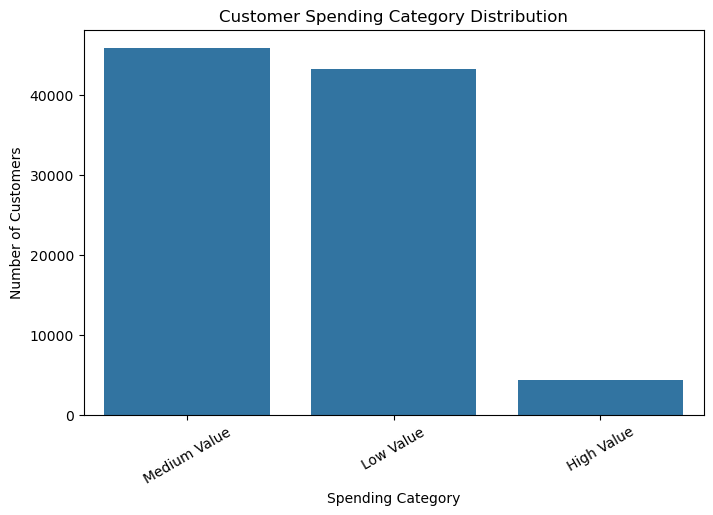

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x="Spending_Category",
    order=rfm["Spending_Category"].value_counts().index
)

plt.title("Customer Spending Category Distribution")
plt.xlabel("Spending Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

plt.show()

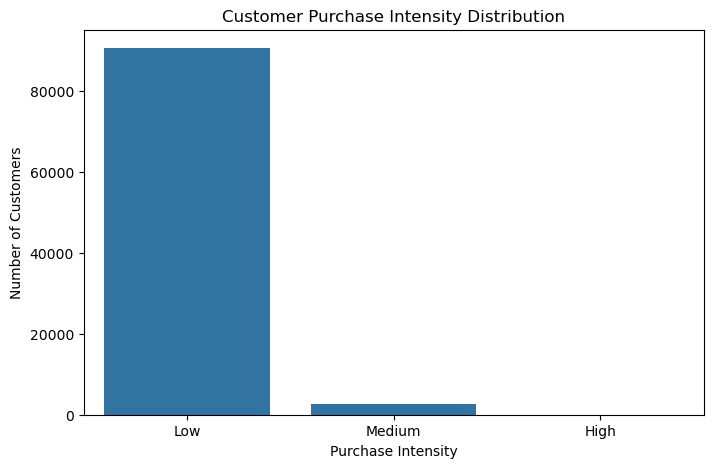

In [22]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x="Purchase_Intensity",
    order=["Low", "Medium", "High"]
)

plt.title("Customer Purchase Intensity Distribution")
plt.xlabel("Purchase Intensity")
plt.ylabel("Number of Customers")

plt.show()

### Step 14 – Recency Category Distribution

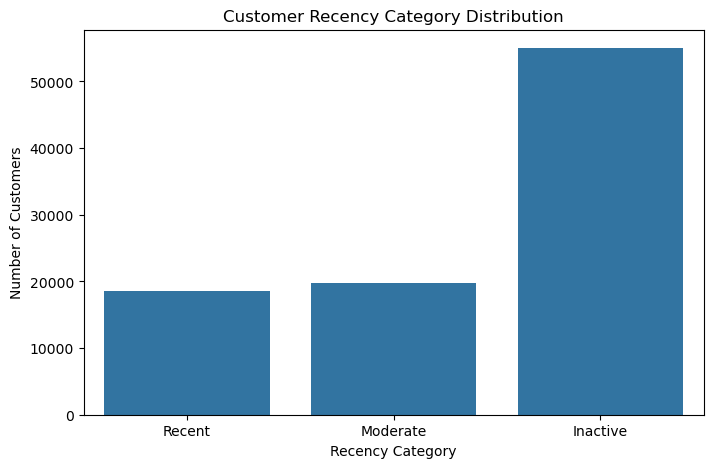

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x="Recency_Category",
    order=["Recent", "Moderate", "Inactive"]
)

plt.title("Customer Recency Category Distribution")
plt.xlabel("Recency Category")
plt.ylabel("Number of Customers")

plt.show()

### Step 15 – Customer Value Score Distribution

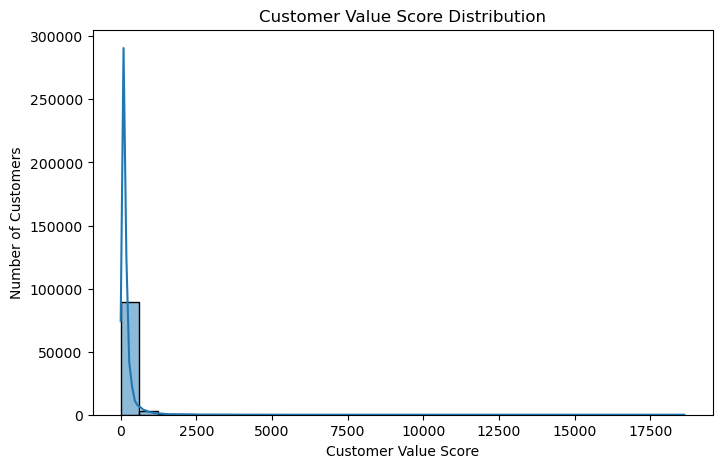

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=rfm,
    x="Customer_Value_Score",
    bins=30,
    kde=True
)

plt.title("Customer Value Score Distribution")
plt.xlabel("Customer Value Score")
plt.ylabel("Number of Customers")

plt.show()

### Step 16 – Customer Loyalty Category Distribution

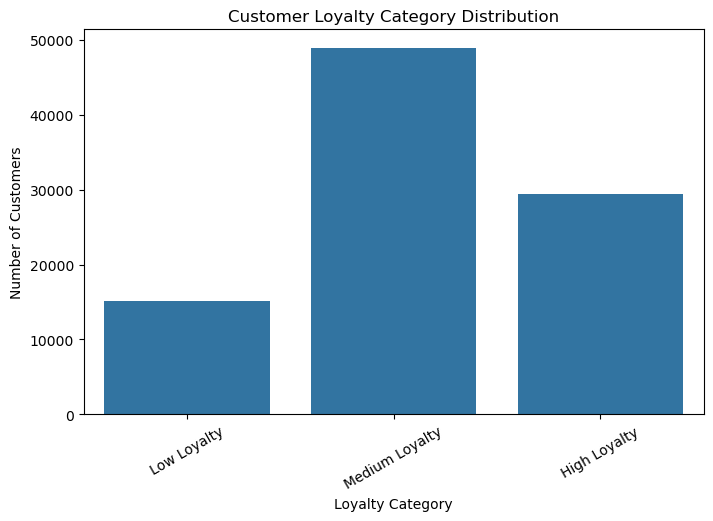

In [25]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x="Loyalty_Category",
    order=["Low Loyalty", "Medium Loyalty", "High Loyalty"]
)

plt.title("Customer Loyalty Category Distribution")
plt.xlabel("Loyalty Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

plt.show()

### Step 17 – Customer Risk Category Distribution

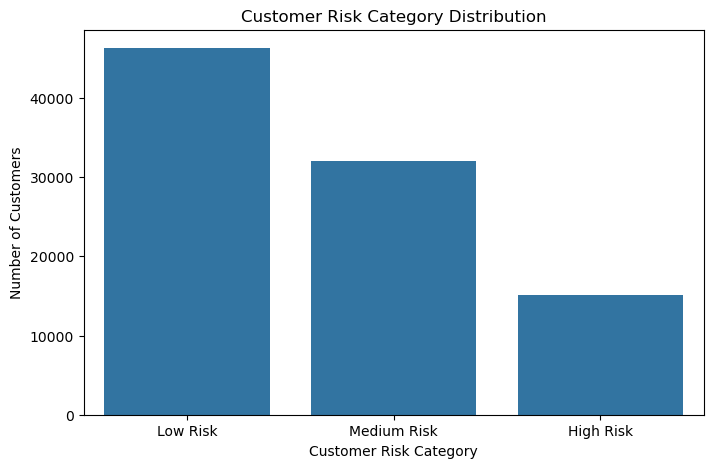

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x="Customer_Risk_Category",
    order=["Low Risk", "Medium Risk", "High Risk"]
)

plt.title("Customer Risk Category Distribution")
plt.xlabel("Customer Risk Category")
plt.ylabel("Number of Customers")

plt.show()

### Step 18 – Customer Engagement Score Distribution

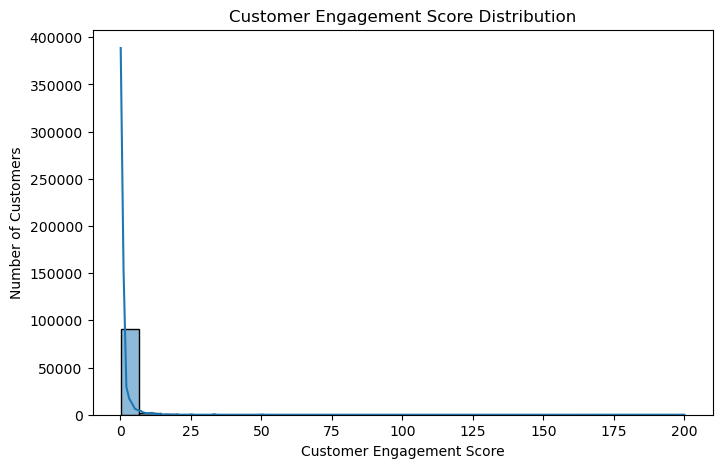

In [27]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=rfm,
    x="Customer_Engagement_Score",
    bins=30,
    kde=True
)

plt.title("Customer Engagement Score Distribution")
plt.xlabel("Customer Engagement Score")
plt.ylabel("Number of Customers")

plt.show()

### Step 19 – Final Feature Validation

In [31]:
print("Final Dataset Shape:", rfm.shape)

print("\nMissing Values:")
print(rfm.isnull().sum())

print("\nDuplicate Rows:", rfm.duplicated().sum())

print("\nTotal Features:", len(rfm.columns))

print("\nFinal Columns:")
print(rfm.columns.tolist())

Final Dataset Shape: (93358, 19)

Missing Values:
customer_unique_id            0
Recency                       0
Frequency                     0
Monetary                      0
R_Score                       0
F_Score                       0
M_Score                       0
RFM_Score                     0
Customer_Segment              0
Average_Spending_Per_Order    0
Customer_Value_Category       0
Purchase_Intensity            0
Spending_Category             0
Customer_Value_Score          0
Loyalty_Category              0
Customer_Risk_Category        0
Customer_Engagement_Score     0
Purchase_Behaviour            0
Recency_Category              0
dtype: int64

Duplicate Rows: 0

Total Features: 19

Final Columns:
['customer_unique_id', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Customer_Segment', 'Average_Spending_Per_Order', 'Customer_Value_Category', 'Purchase_Intensity', 'Spending_Category', 'Customer_Value_Score', 'Loyalty_Category', 'Cust

### Step 20 – Export Final Feature-Engineered Dataset

In [29]:
rfm.to_csv(
    "customer_feature_engineered.csv",
    index=False
)

print("Feature-engineered dataset saved successfully!")

Feature-engineered dataset saved successfully!
